# Notebook 07 — Model Explainability, SHAP & Fairness Audit
Credit Risk Scoring & Default Prediction | UCI Default of Credit Card Clients

## Objetivo
Explicar el XGBoost optimizado del Notebook 06 y auditar su comportamiento por segmentos. No se reentrena, recalibra ni selecciona umbral con test. Se comparan dos políticas ya disponibles: 0.5 y el umbral congelado del Notebook 06. La evaluación es retrospectiva: test ya fue observado. Los atributos demográficos se usan únicamente para auditoría, nunca para scoring ni umbrales diferenciados. Datos históricos de Taiwán, 2005; PD del siguiente mes, no anual. No es una certificación de equidad ni un sistema de decisión real.

## 1. Configuración
Usa el mismo kernel de Notebook 06. Si falta SHAP, ejecuta `%pip install shap` y reinicia el kernel. Evita actualizar todas las dependencias del entorno. Los archivos joblib deben proceder exclusivamente de tu proyecto de confianza.

In [1]:
from pathlib import Path
import json, sys
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import joblib, shap, sklearn, xgboost
from scipy.special import expit, logit
from sklearn.metrics import (roc_auc_score, average_precision_score, brier_score_loss,
    confusion_matrix, f1_score, log_loss)
from IPython.display import display
SEED = 42
MAX_SHAP = 1000
MIN_GROUP = 50
MIN_CLASS = 20
root = Path.cwd()
if root.name.lower() == 'notebooks': root = root.parent
processed = root / 'data' / 'processed'
models = root / 'models'
figures = root / 'reports' / 'figures'
figures.mkdir(parents=True, exist_ok=True)
print(root, sys.executable, 'SHAP:', shap.__version__, 'XGB:', xgboost.__version__)
plt.rcParams.update({'figure.dpi': 110, 'axes.spines.top': False, 'axes.spines.right': False})
def save_plot(name):
    plt.tight_layout()
    plt.savefig(figures / ('07_'+name+'.png'), dpi=150, bbox_inches='tight')
    plt.show()
    plt.close()

C:\Users\pirom\anaconda3\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


C:\Users\pirom\OneDrive\Documentos\Proyectos\credit_risk_scoring C:\Users\pirom\anaconda3\python.exe SHAP: 0.51.0 XGB: 3.3.0


## 2. Cargar artefactos y reconciliar datos
El Notebook 06 guarda un diccionario con pipeline, calibrador y configuración. El Notebook 03 guarda los atributos de auditoría por `row_id`. La unión exige correspondencia exacta y no depende del orden de filas.

In [2]:
manifest = json.loads((processed/'feature_manifest.json').read_text(encoding='utf-8'))
bundle = joblib.load(models/'optimized_xgboost.joblib')
pipe, calibrator, config = bundle['pipeline'], bundle['calibrator'], bundle['config']
features = manifest['features']; target = manifest['target']
audit_cols = manifest['audit_only']
assert config['features'] == features and config['target'] == target
assert len(set(features)) == len(features)
assert set(features).isdisjoint(audit_cols + [target, 'row_id'])
assert list(pipe.classes_) == [0,1]
assert list(pipe.feature_names_in_) == features
assert type(pipe.named_steps['model']).__name__ == 'XGBClassifier'
assert config['test_used_for_selection'] is False
threshold = float(config['threshold'])
assert 0 <= threshold <= 1
method = config['method']
test = pd.read_csv(processed/'credit_risk_test_features.csv').set_index('row_id', verify_integrity=True)
audit = pd.read_csv(processed/'credit_risk_test_audit.csv').set_index('row_id', verify_integrity=True)
assert test.index.notna().all() and audit.index.notna().all()
assert set(test.index) == set(audit.index), 'IDs de auditoría no coinciden'
assert set(test.columns) == set(features+[target])
assert set(audit_cols).issubset(audit.columns)
audit = audit.loc[test.index, audit_cols].copy()
assert test[target].isin([0,1]).all() and test[target].nunique()==2
X = test[features].apply(pd.to_numeric, errors='raise').replace([np.inf,-np.inf],np.nan)
y = test[target].astype(int)
print('Test:', X.shape, 'Calibrador:', method, 'Umbral congelado:', threshold)
print('Demografía excluida del modelo:', audit_cols)

Test: (6000, 34) Calibrador: raw Umbral congelado: 0.04
Demografía excluida del modelo: ['SEX', 'AGE', 'EDUCATION', 'MARRIAGE']


C:\Users\pirom\AppData\Local\Temp\ipykernel_29740\2092083765.py:16: Pandas4Warning: The 'verify_integrity' keyword in DataFrame.set_index is deprecated and will be removed in a future version. Directly check the result.index.is_unique instead.
  test = pd.read_csv(processed/'credit_risk_test_features.csv').set_index('row_id', verify_integrity=True)
C:\Users\pirom\AppData\Local\Temp\ipykernel_29740\2092083765.py:17: Pandas4Warning: The 'verify_integrity' keyword in DataFrame.set_index is deprecated and will be removed in a future version. Directly check the result.index.is_unique instead.
  audit = pd.read_csv(processed/'credit_risk_test_audit.csv').set_index('row_id', verify_integrity=True)


## 3. Reconstruir PD de producción
Reproducimos exactamente la transformación del Notebook 06 (incluido clipping). Si existe el CSV de scores, comprobamos que coincide. No elegimos un umbral nuevo.

In [3]:
def calibrated_pd(p):
    p = np.asarray(p)
    if method == 'platt':
        p = calibrator.predict_proba(logit(np.clip(p,1e-6,1-1e-6)).reshape(-1,1))[:,1]
    elif method == 'isotonic': p = calibrator.predict(p)
    elif method != 'raw': raise ValueError(method)
    return np.clip(p,1e-6,1-1e-6)
raw = pipe.predict_proba(X)[:,1]
pd_final = calibrated_pd(raw)
assert np.isfinite(pd_final).all()
score_path = processed/'06_test_scores.csv'
if score_path.exists():
    saved = pd.read_csv(score_path).set_index('row_id', verify_integrity=True)
    assert set(saved.index)==set(test.index)
    np.testing.assert_allclose(saved.loc[test.index,'PD'], pd_final, atol=1e-6)
    np.testing.assert_array_equal(saved.loc[test.index,'DEFAULT'], y)
print('PD promedio:', pd_final.mean(), 'Default observado:', y.mean())
print('Tasa de alertas umbral 0.5:', (pd_final>=.5).mean(), 'Política 06:', (pd_final>=threshold).mean())

PD promedio: 0.2201477 Default observado: 0.22116666666666668
Tasa de alertas umbral 0.5: 0.12 Política 06: 0.9928333333333333


C:\Users\pirom\AppData\Local\Temp\ipykernel_29740\86461724.py:13: Pandas4Warning: The 'verify_integrity' keyword in DataFrame.set_index is deprecated and will be removed in a future version. Directly check the result.index.is_unique instead.
  saved = pd.read_csv(score_path).set_index('row_id', verify_integrity=True)


## 4. TreeSHAP: explicar el margen del modelo
TreeExplainer explica el margen bruto (log-odds), no la probabilidad calibrada. La suma de contribuciones y el valor base reconstruye el margen; sigmoid lo convierte a PD sin calibrar. Platt o isotónica se aplican después y no se atribuyen a variables aquí. Usamos una muestra aleatoria reproducible de hasta 1,000 clientes de test para limitar memoria. El preprocesamiento es el imputador ya ajustado, nunca se ajusta de nuevo. Las características correlacionadas pueden compartir atribuciones; SHAP no prueba causalidad.

In [4]:
sample = X.sample(n=min(MAX_SHAP,len(X)),random_state=SEED)
pre = pipe[:-1]
model = pipe.named_steps['model']
transformed = pre.transform(sample)
try:
    names = list(pre.get_feature_names_out(features))
except AttributeError:
    if transformed.shape[1] != len(features): raise ValueError('No se puede reconstruir esquema tras imputación')
    names = features
assert transformed.shape[1] == len(names)
Z = pd.DataFrame(transformed, columns=names, index=sample.index)
explainer = shap.TreeExplainer(model, model_output='raw', feature_perturbation='tree_path_dependent')
sv = explainer(Z)
assert sv.values.shape == Z.shape, 'Se esperaba SHAP binario en margen bruto'
margin = np.asarray(model.predict(transformed, output_margin=True)).ravel()
reconstructed = np.asarray(sv.base_values).reshape(-1) + sv.values.sum(axis=1)
np.testing.assert_allclose(reconstructed, margin, atol=2e-4, rtol=1e-4)
np.testing.assert_allclose(expit(reconstructed), pipe.predict_proba(sample)[:,1], atol=2e-5)
print('Aditividad verificada para', len(Z), 'clientes. Error máximo:', np.max(np.abs(reconstructed-margin)))

Aditividad verificada para 1000 clientes. Error máximo: 2.3841858e-06


## 5. Importancia global y Beeswarm
La media de |SHAP| mide magnitud de influencia en el margen para esta muestra. Beeswarm muestra signo, dispersión y valor de cada característica. A la derecha aumenta el margen de incumplimiento; no significa que aumentar artificialmente la variable cause un cambio equivalente.

,feature,mean_abs_shap
1,PAY_0,0.367061
19,late_months,0.275237
20,late_2plus_months,0.186792
0,LIMIT_BAL,0.089325
29,utilization_recent,0.085681
24,bill_std,0.077961
28,zero_payment_months,0.072895
26,payment_mean,0.059421
7,BILL_AMT1,0.057725
30,utilization_mean,0.053470


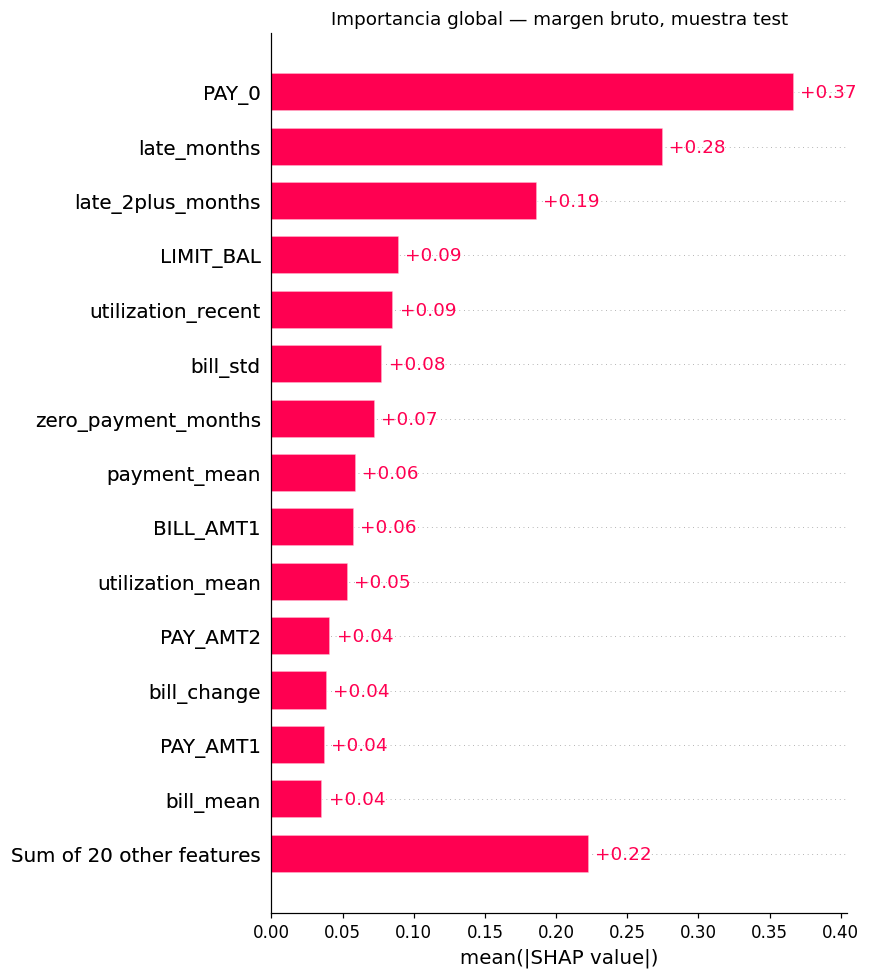

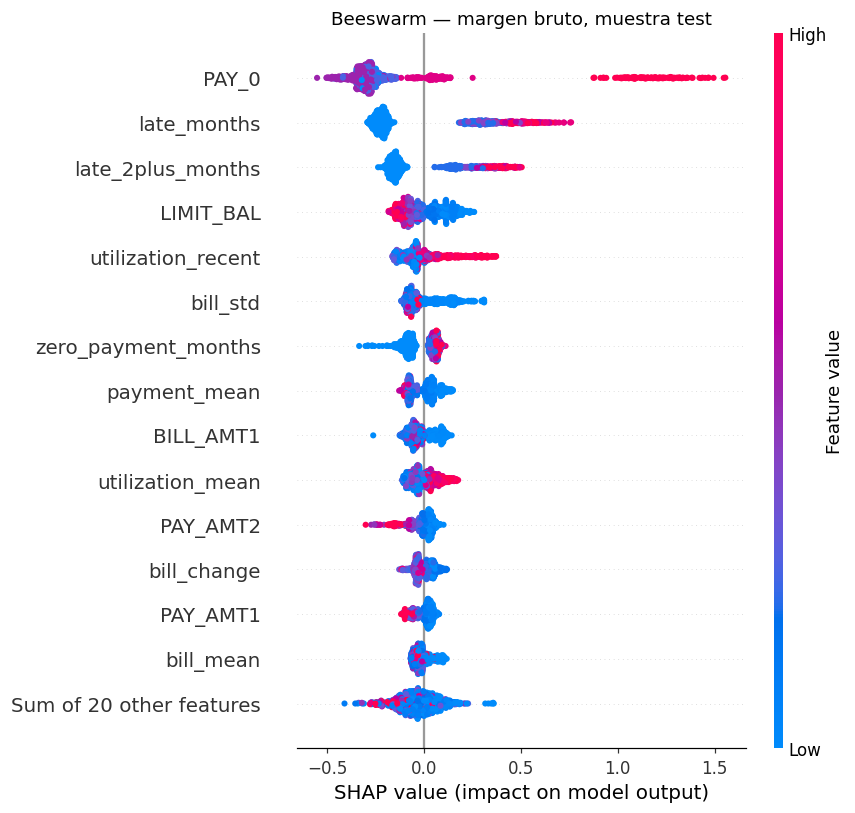

In [7]:
importance = pd.DataFrame({'feature':names,'mean_abs_shap':np.abs(sv.values).mean(axis=0)}).sort_values('mean_abs_shap',ascending=False)
display(importance.head(15))
shap.plots.bar(sv,max_display=15,show=False)
plt.title('Importancia global — margen bruto, muestra test')
save_plot('shap_importance')
shap.plots.beeswarm(sv,max_display=15,show=False)
plt.title('Beeswarm — margen bruto, muestra test')
save_plot('shap_beeswarm')

## 6. Dependence Plot
Seleccionamos hasta tres indicadores financieros relevantes disponibles. Si faltan, usamos los más importantes. Cada punto representa un cliente. La relación no es causal y los valores provienen del imputador.

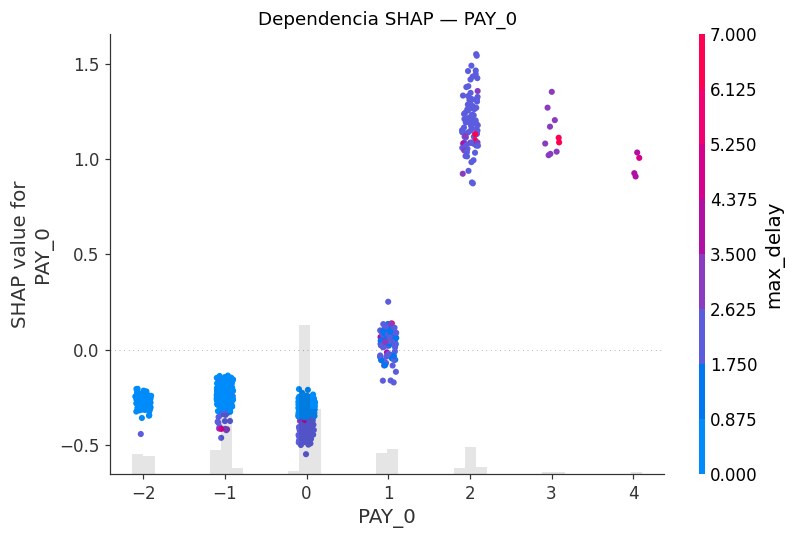

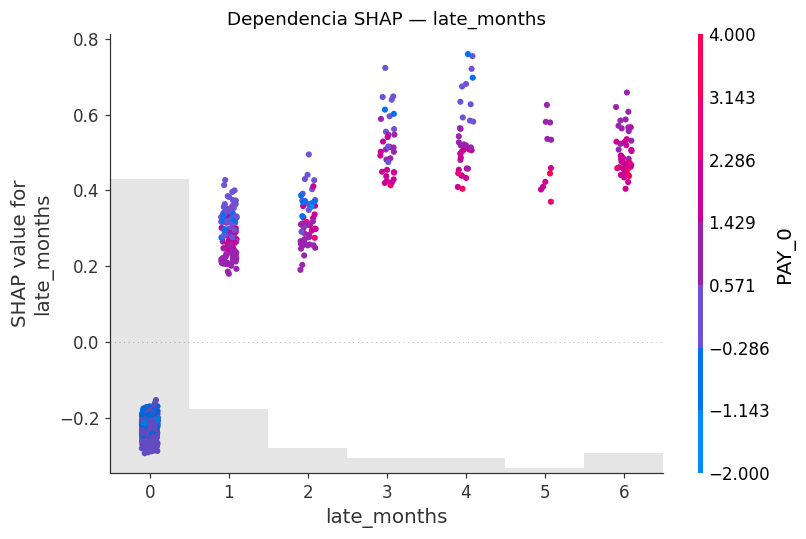

Done: <matplotlib.backends.backend_agg.RendererAgg object at 0x0000025DBA2A5820>

In [9]:
selected = [f for f in ['PAY_0','late_months','utilization_recent'] if f in names]
if not selected: selected = importance.feature.head(3).tolist()
for feature in selected:
    shap.plots.scatter(sv[:,feature],color=sv,show=False)
    plt.title(f'Dependencia SHAP — {feature}')
    save_plot('dependence_'+feature)

## 7. Explicabilidad individual (Waterfall)
Elegimos casos de riesgo alto, mediano y bajo dentro de la muestra, no por resultado favorable. Mostramos PD original y calibrada, etiqueta observada y decisión. Las barras explican log-odds, no puntos porcentuales de PD ni razones regulatorias de rechazo.

bajo | row_id: 6722 | PD raw: 0.0366 | PD final: 0.0366 | real: 0 | alerta: 0


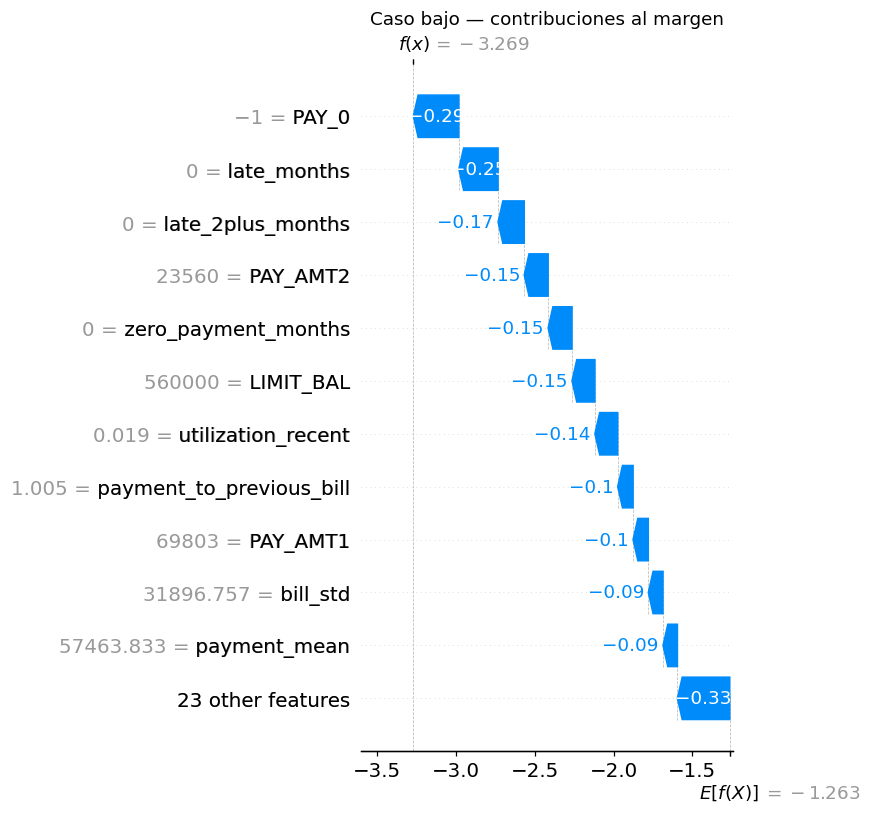

medio | row_id: 1788 | PD raw: 0.1537 | PD final: 0.1537 | real: 0 | alerta: 1


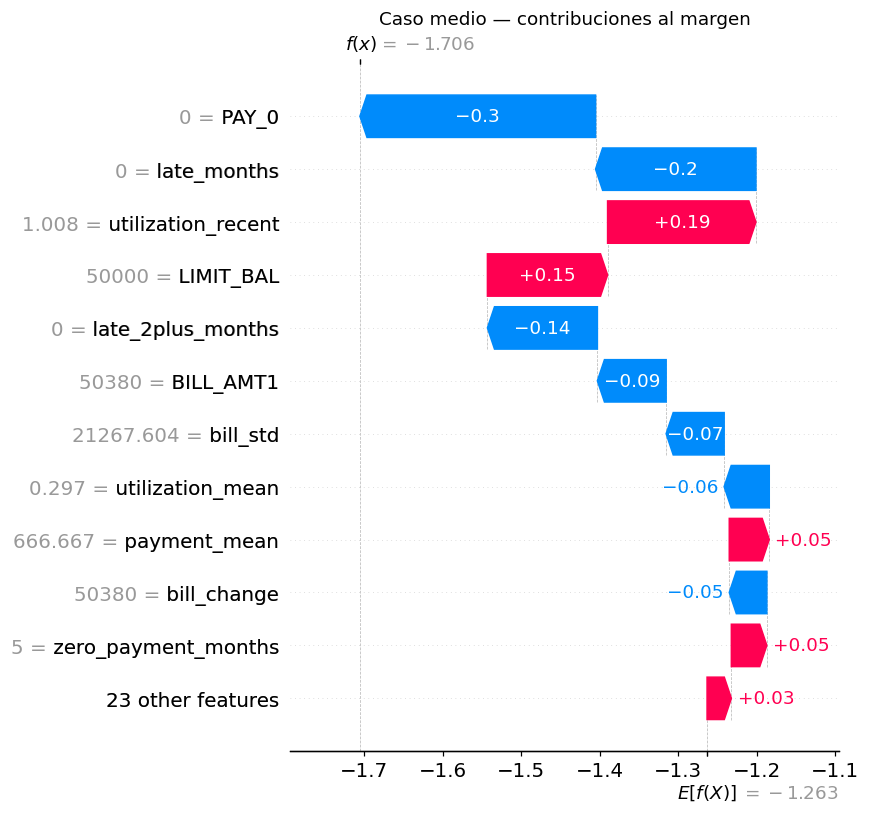

alto | row_id: 29770 | PD raw: 0.8338 | PD final: 0.8338 | real: 1 | alerta: 1


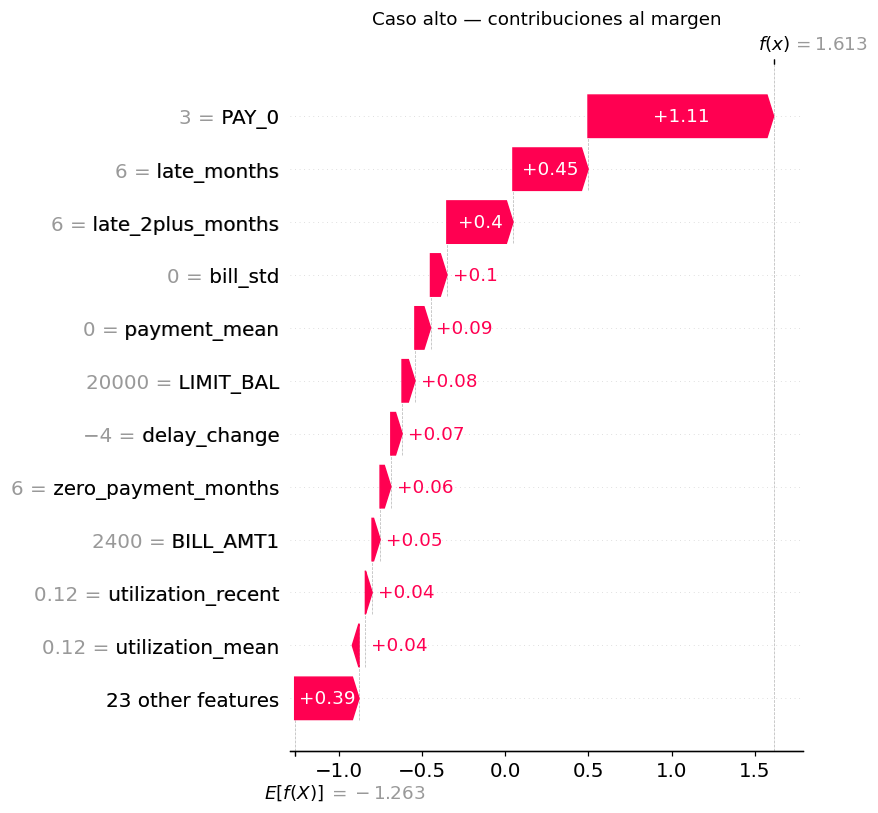

In [18]:
sample_raw = pipe.predict_proba(sample)[:,1]
order = np.argsort(sample_raw)
positions = {'bajo':int(order[0]),'medio':int(order[len(order)//2]),'alto':int(order[-1])}
local_rows=[]
for label,i in positions.items():
    rid=sample.index[i]; p=float(sample_raw[i]); pc=float(calibrated_pd([p])[0])
    print(label, '| row_id:',rid,'| PD raw:',round(p,4),'| PD final:',round(pc,4),'| real:',int(y.loc[rid]),'| alerta:',int(pc>=threshold))
    shap.plots.waterfall(sv[i],max_display=12,show=False)
    plt.title(f'Caso {label} — contribuciones al margen')
    save_plot('waterfall_'+label)
    for j,f in enumerate(names):
        local_rows.append({'case':label,'row_id':rid,'feature':f,'value_imputed':Z.iloc[i,j], 'shap_log_odds':sv.values[i,j], 'base_log_odds':float(np.asarray(sv.base_values).reshape(-1)[i]),'pd_raw':p,'pd_calibrated':pc})
local = pd.DataFrame(local_rows)

## 8. Preparar segmentos de auditoría
Codificación UCI: sexo 1 hombre, 2 mujer; educación 1 posgrado, 2 universidad, 3 secundaria, 4 otros; códigos no documentados agrupados por separado. Estado civil 1 casado, 2 soltero, 3 otros. Edad agrupada en tramos ilustrativos, no categorías legales. Los datos faltantes o códigos inesperados permanecen visibles. No se usa ningún atributo de auditoría para alterar decisiones.

In [19]:
def category(s, mapping):
    v = pd.to_numeric(s,errors='coerce')
    return v.map(mapping).fillna('Desconocido / otro código')
segments = pd.DataFrame(index=test.index)
segments['sexo'] = category(audit.SEX,{1:'Hombre',2:'Mujer'})
segments['educacion'] = category(audit.EDUCATION,{1:'Posgrado',2:'Universidad',3:'Secundaria',4:'Otros'})
segments['estado_civil'] = category(audit.MARRIAGE,{1:'Casado',2:'Soltero',3:'Otros'})
ages=pd.to_numeric(audit.AGE,errors='coerce')
segments['edad'] = pd.cut(ages.where(ages.between(18,100)),bins=[18,30,40,50,60,101],right=False,labels=['18–29','30–39','40–49','50–59','60+']).astype(object).fillna('Desconocido')
segments['sexo_x_edad']=segments.sexo.astype(str)+' | '+segments.edad.astype(str)
display(segments.apply(lambda s:s.value_counts()).fillna(0).astype(int))

,sexo,educacion,estado_civil,edad,sexo_x_edad
18–29,0,0,0,1912,0
30–39,0,0,0,2198,0
40–49,0,0,0,1341,0
50–59,0,0,0,473,0
60+,0,0,0,76,0
Casado,0,0,2767,0,0
Desconocido / otro código,0,56,7,0,0
Hombre,2402,0,0,0,0
Hombre | 18–29,0,0,0,0,669
Hombre | 30–39,0,0,0,0,907


## 9. Métricas por grupo y política
TPR = recall; FPR = falsos positivos / no incumplidores; FNR = 1−TPR. Tasa de alerta = fracción clasificada como riesgo, no aprobación. Evaluamos también precisión, AUC, AP, Brier y diferencia PD media − default observado. Los intervalos Wilson al 95% reflejan variabilidad binomial aproximada (no ajustados por comparaciones múltiples). Métricas condicionales no definidas se dejan NaN, no cero. Grupos pequeños se marcan y excluyen de las brechas resumidas; no desaparecen de la tabla.

In [20]:
def div(a,b): return a/b if b else np.nan
def wilson(k,n,z=1.96):
    if not n: return (np.nan,np.nan)
    p=k/n; den=1+z*z/n; center=(p+z*z/(2*n))/den
    half=z*np.sqrt(p*(1-p)/n+z*z/(4*n*n))/den
    return max(0,center-half), min(1,center+half)
def group_metrics(yy,pp,t):
    yy=np.asarray(yy); pp=np.asarray(pp); pred=pp>=t
    tn,fp,fn,tp=confusion_matrix(yy,pred,labels=[0,1]).ravel()
    n=len(yy); pos=tp+fn; neg=tn+fp
    lo,hi=wilson(tp,pos); flo,fhi=wilson(fp,neg)
    return dict(n=n,defaults=pos,nondefaults=neg,tn=tn,fp=fp,fn=fn,tp=tp,
        prevalence=yy.mean(),pd_mean=pp.mean(),calibration_gap=pp.mean()-yy.mean(),
        alert_rate=pred.mean(),precision=div(tp,tp+fp),tpr=div(tp,pos),fnr=div(fn,pos),fpr=div(fp,neg),
        tpr_lo=lo,tpr_hi=hi,fpr_lo=flo,fpr_hi=fhi,
        auc=roc_auc_score(yy,pp) if pos and neg else np.nan,
        ap=average_precision_score(yy,pp) if pos and neg else np.nan,
        brier=brier_score_loss(yy,pp), log_loss=log_loss(yy,pp,labels=[0,1]),
        eligible=bool(n>=MIN_GROUP and pos>=MIN_CLASS and neg>=MIN_CLASS))
policies={'reference_05':.5,'frozen_06':threshold}
rows=[]
for policy,t in policies.items():
    rows.append(dict(policy=policy,attribute='total',group='Todos',threshold=t,**group_metrics(y,pd_final,t)))
    for attr in segments:
        for group in segments[attr].unique():
            mask=segments[attr].eq(group).to_numpy()
            rows.append(dict(policy=policy,attribute=attr,group=group,threshold=t,**group_metrics(y.to_numpy()[mask],pd_final[mask],t)))
fairness=pd.DataFrame(rows)
for (policy,attr),g in fairness[fairness.attribute!='total'].groupby(['policy','attribute']):
    assert g.n.sum()==len(y) and g.defaults.sum()==y.sum()
cols=['policy','attribute','group','n','defaults','prevalence','alert_rate','precision','tpr','fpr','fnr','auc','ap','brier','calibration_gap','eligible']
display(fairness[cols].round(4))

,policy,attribute,group,n,defaults,prevalence,alert_rate,precision,tpr,fpr,fnr,auc,ap,brier,calibration_gap,eligible
0,reference_05,total,Todos,6000,1327,0.2212,0.1200,0.6639,0.3602,0.0518,0.6398,0.7803,0.5588,0.1348,-0.0010,True
1,reference_05,sexo,Hombre,2402,561,0.2336,0.1241,0.6510,0.3458,0.0565,0.6542,0.7728,0.5459,0.1434,-0.0078,True
2,reference_05,sexo,Mujer,3598,766,0.2129,0.1173,0.6730,0.3708,0.0487,0.6292,0.7853,0.5709,0.1291,0.0035,True
3,reference_05,educacion,Universidad,2774,656,0.2365,0.1420,0.6751,0.4055,0.0604,0.5945,0.7826,0.5825,0.1388,-0.0002,True
4,reference_05,educacion,Posgrado,2130,405,0.1901,0.0836,0.6910,0.3037,0.0319,0.6963,0.7971,0.5483,0.1187,0.0009,True
5,reference_05,educacion,Secundaria,1014,261,0.2574,0.1410,0.6154,0.3372,0.0730,0.6628,0.7287,0.5322,0.1625,-0.0146,True
6,reference_05,educacion,Otros,26,1,0.0385,0.0769,0.5000,1.0000,0.0400,0.0000,0.9600,0.5000,0.0409,0.1255,False
7,reference_05,educacion,Desconocido / otro código,56,4,0.0714,0.0536,0.0000,0.0000,0.0577,1.0000,0.5673,0.1293,0.0896,0.0749,False
8,reference_05,estado_civil,Soltero,3158,647,0.2049,0.1200,0.6359,0.3725,0.0550,0.6275,0.7776,0.5312,0.1289,0.0160,True
9,reference_05,estado_civil,Casado,2767,668,0.2414,0.1196,0.7039,0.3488,0.0467,0.6512,0.7869,0.5957,0.1415,-0.0223,True


## 10. Brechas de equidad y visualizaciones
Comparamos max−min de tasas de alerta, TPR y FPR; equalized odds gap = máximo de las brechas TPR/FPR. La razón min/max de tasa de alerta es descriptiva (no regla legal de aprobación). Si la política marca a todos, ciertas brechas pueden parecer pequeñas artificialmente: revisar la tasa de alerta, precisión y utilidad. No afirmar discriminación ni ausencia de ella por una sola métrica. Diferencias de prevalencia, tamaño y contexto requieren investigación.

,policy,attribute,groups_eligible,groups_total,alert_rate_gap,tpr_gap,fpr_gap,fnr_gap,brier_gap,calibration_gap_gap,equalized_odds_gap,alert_rate_ratio
0,frozen_06,edad,5,5,0.0104,0.0022,0.0136,0.0022,0.0417,0.0755,0.0136,0.9896
1,frozen_06,educacion,3,5,0.0074,0.0025,0.0082,0.0025,0.0439,0.0155,0.0082,0.9926
2,frozen_06,estado_civil,2,4,0.0006,0.0015,0.0016,0.0015,0.0126,0.0384,0.0016,0.9994
3,frozen_06,sexo,2,2,0.0019,0.0018,0.0022,0.0018,0.0143,0.0114,0.0022,0.9981
4,frozen_06,sexo_x_edad,8,10,0.0082,0.0049,0.0107,0.0049,0.0307,0.0607,0.0107,0.9917
5,reference_05,edad,5,5,0.0465,0.1057,0.0276,0.1057,0.0417,0.0755,0.1057,0.6776
6,reference_05,educacion,3,5,0.0585,0.1018,0.0412,0.1018,0.0439,0.0155,0.1018,0.5884
7,reference_05,estado_civil,2,4,0.0004,0.0237,0.0083,0.0237,0.0126,0.0384,0.0237,0.9968
8,reference_05,sexo,2,2,0.0068,0.0249,0.0078,0.0249,0.0143,0.0114,0.0249,0.9454
9,reference_05,sexo_x_edad,8,10,0.0684,0.1634,0.0310,0.1634,0.0307,0.0607,0.1634,0.5502


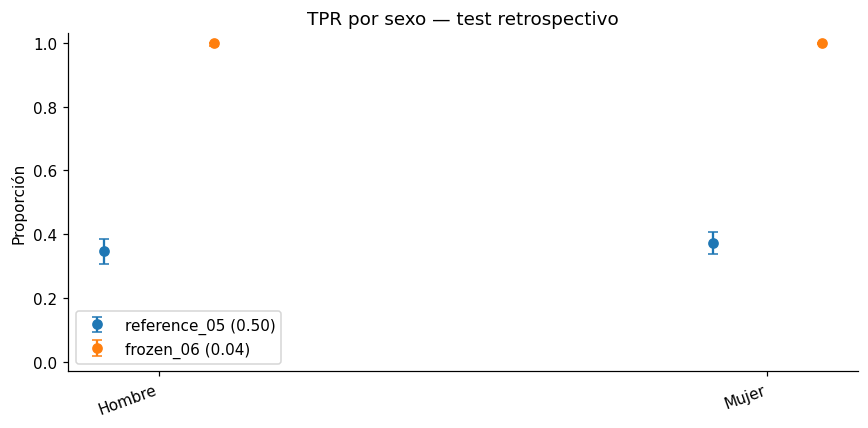

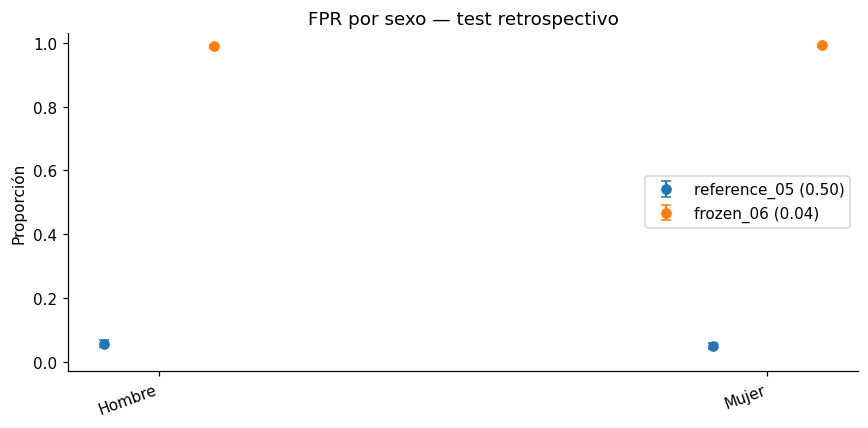

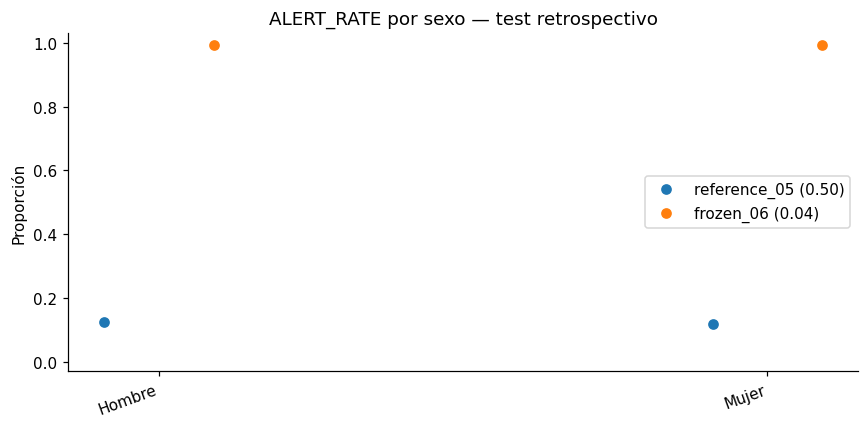

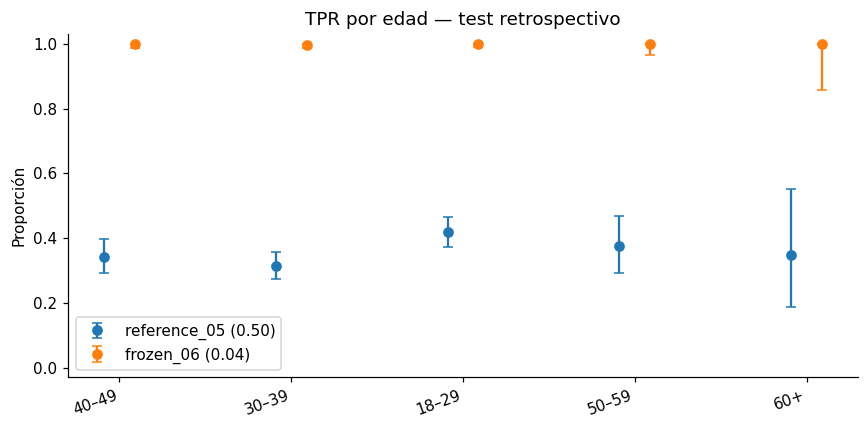

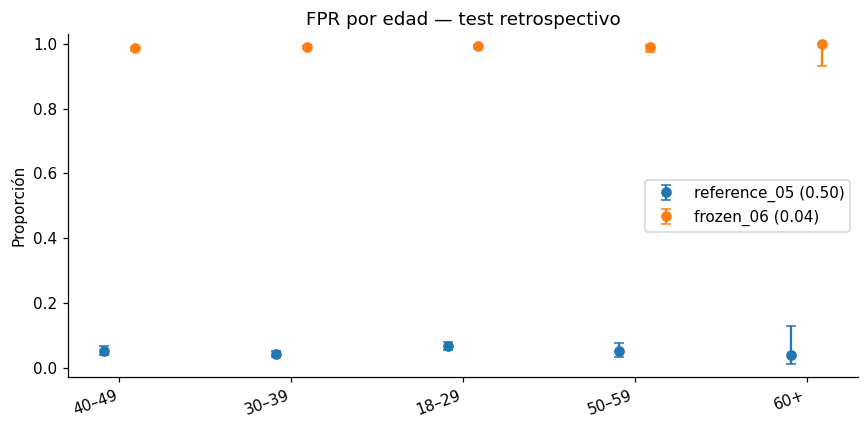

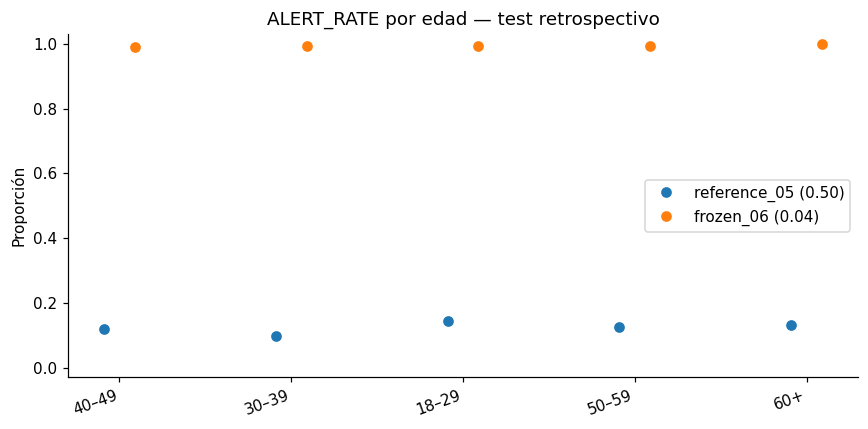

In [21]:
gaps=[]
for (policy,attr),g0 in fairness[fairness.attribute!='total'].groupby(['policy','attribute']):
    g=g0[g0.eligible]
    row={'policy':policy,'attribute':attr,'groups_eligible':len(g),'groups_total':len(g0)}
    for metric in ['alert_rate','tpr','fpr','fnr','brier','calibration_gap']:
        row[metric+'_gap']=g[metric].max()-g[metric].min() if len(g)>=2 else np.nan
    row['equalized_odds_gap']=max(row['tpr_gap'],row['fpr_gap'])
    row['alert_rate_ratio']=div(g.alert_rate.min(),g.alert_rate.max()) if len(g)>=2 else np.nan
    gaps.append(row)
gaps=pd.DataFrame(gaps)
display(gaps.round(4))
for attr in ['sexo','edad']:
    g=fairness[(fairness.attribute==attr)&fairness.eligible]
    if g.empty: 
        continue
    for metric in ['tpr','fpr','alert_rate']:
        fig,ax=plt.subplots(figsize=(8,4))
        for i,(policy,t) in enumerate(policies.items()):
            h=g[g.policy==policy]; xx=np.arange(len(h))+(i-.5)*.18
            err=None
            if metric in ['tpr','fpr']:
                err=np.maximum(0,np.vstack([h[metric]-h[metric+'_lo'],h[metric+'_hi']-h[metric]]))
            ax.errorbar(xx,h[metric],yerr=err,fmt='o',capsize=3,label=f'{policy} ({t:.2f})')
        ax.set_xticks(np.arange(len(h)),h.group,rotation=20,ha='right')
        ax.set(ylim=(-.03,1.03),ylabel='Proporción',title=f'{metric.upper()} por {attr} — test retrospectivo');ax.legend()
        save_plot(f'fairness_{attr}_{metric}')

## 11. Guardar resultados y diagnóstico
Los archivos de casos individuales contienen IDs internos y datos financieros; no subirlos a un repositorio público. Las tablas agregadas son mejores para el portafolio, previa revisión. El modelo y la política del Notebook 06 permanecen sin cambios.

In [22]:
importance.to_csv(processed/'07_shap_importance.csv',index=False)
local.to_csv(processed/'07_shap_local_cases.csv',index=False)
fairness.to_csv(processed/'07_fairness_metrics.csv',index=False)
gaps.to_csv(processed/'07_fairness_gaps.csv',index=False)
metadata={'model':'optimized_xgboost.joblib','method':method,'threshold':threshold,'reference_threshold':.5,
    'shap_scale':'raw log-odds','sample_size':len(Z),'seed':SEED,'min_group':MIN_GROUP,'min_class':MIN_CLASS,
    'test_previously_observed':True,'shap_version':shap.__version__,'sklearn_version':sklearn.__version__, 'xgboost_version':xgboost.__version__}
(processed/'07_audit_metadata.json').write_text(json.dumps(metadata,indent=2),encoding='utf-8')
print('Top 3 variables SHAP:',importance.feature.head(3).tolist())
display(fairness.loc[fairness.attribute=='total',cols].round(4))
print('Brechas evaluables:',gaps.equalized_odds_gap.notna().sum())
print('Resultados guardados en',processed)

Top 3 variables SHAP: ['PAY_0', 'late_months', 'late_2plus_months']


,policy,attribute,group,n,defaults,prevalence,alert_rate,precision,tpr,fpr,fnr,auc,ap,brier,calibration_gap,eligible
0,reference_05,total,Todos,6000,1327,0.2212,0.1200,0.6639,0.3602,0.0518,0.6398,0.7803,0.5588,0.1348,-0.001,True
27,frozen_06,total,Todos,6000,1327,0.2212,0.9928,0.2226,0.9992,0.9910,0.0008,0.7803,0.5588,0.1348,-0.001,True


Brechas evaluables: 10
Resultados guardados en C:\Users\pirom\OneDrive\Documentos\Proyectos\credit_risk_scoring\data\processed
